# US Montessori Private Schools, 1989-2024: Starter Notebook

![cover](https://raw.githubusercontent.com/montessoritheory/us-montessori-private-schools/main/images/cover.png)

This notebook loads the dataset and answers four quick questions with the official numbers from the **NCES Private School Universe Survey (PSS)**:

1. How has the number of Montessori private schools changed since 1989?
2. Which states and cities have the most schools today?
3. How many schools belong to AMS or AMI?
4. Where are the schools, on a map?

Each row of the main file is one Montessori school in one survey wave. A school is counted when it calls itself Montessori, reports a Montessori association, or has "Montessori" in its name. Public Montessori schools are not in the PSS, so they are not here.

In [1]:
import os, pandas as pd, matplotlib.pyplot as plt

# works on Kaggle, and anywhere else straight from GitHub
KAGGLE = "/kaggle/input/us-montessori-private-schools"
LOCAL = next((p for p in ["data", "../data"] if os.path.exists(p)), "data")
GITHUB = "https://raw.githubusercontent.com/montessoritheory/us-montessori-private-schools/main/data"
BASE = KAGGLE if os.path.exists(KAGGLE) else (LOCAL if os.path.exists(LOCAL) else GITHUB)

def load(name, **kw):
    return pd.read_csv(f"{BASE}/{name}", **kw)

schools = load("montessori_private_schools_1989_2024.csv", low_memory=False, dtype={"school_id": str, "zip5": str, "county_fips": str})
latest = load("montessori_private_schools_2023_24.csv", dtype={"school_id": str, "zip5": str, "county_fips": str})
nat = load("national_by_year.csv")
states = load("by_state_2023_24.csv")
cities = load("by_city_2023_24.csv")
print(f"{len(schools):,} school-year records, {schools.survey_year.nunique()} survey waves, {len(latest):,} schools in 2023-24")

37,543 school-year records, 18 survey waves, 2,070 schools in 2023-24


In [2]:
plt.rcParams.update({"figure.facecolor": "#F7F3EC", "axes.facecolor": "#F7F3EC", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#E4DED3", "font.size": 12})
TC, BLUE, OLIVE = "#B4532F", "#1F72B8", "#7F9A1F" 

## 1. The national trend

`montessori_schools` counts the schools in each public file. `weighted_estimate_program_type` is the NCES weighted estimate of schools whose type is Montessori, the figure NCES publishes (for 2021-22 it is 2,441, the number in NCES Table 16). Compare trends from 1995-96 on: the earliest waves covered fewer schools and have no weights.

In [3]:
nat[["survey_year", "montessori_schools", "montessori_program_type", "weighted_estimate_program_type", "share_of_private_schools_pct"]]

,survey_year,montessori_schools,montessori_program_type,weighted_estimate_program_type,share_of_private_schools_pct
0,1989-90,670,588,NaN,3.23
1,1991-92,836,739,NaN,3.52
2,1993-94,1901,1548,NaN,5.19
3,1995-96,2191,2064,2509.0,7.65
4,1997-98,2254,2137,2311.0,7.45
5,1999-00,2205,2046,2305.0,7.56
6,2001-02,2324,2183,2750.0,7.54
7,2003-04,2274,2125,2481.0,7.56
8,2005-06,2464,2206,2758.0,8.27
9,2007-08,2454,2201,2650.0,8.63


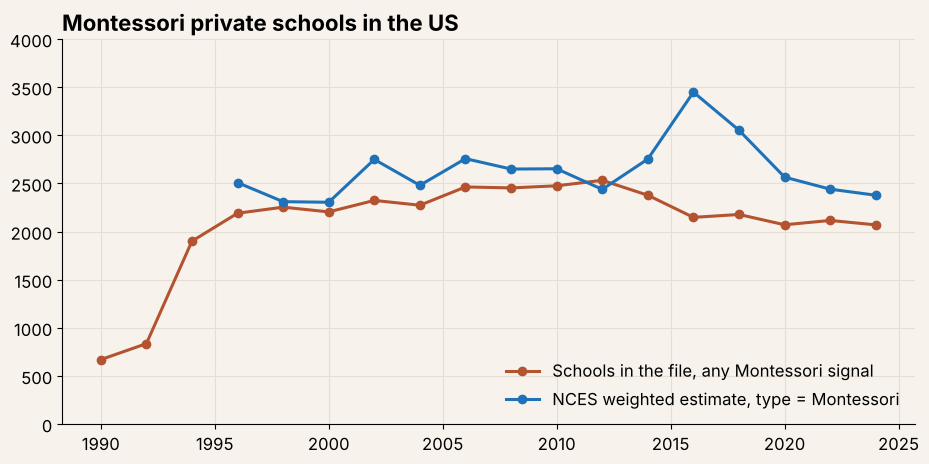

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(nat.school_year_end, nat.montessori_schools, color=TC, lw=2.2, marker="o", label="Schools in the file, any Montessori signal")
ax.plot(nat.school_year_end, nat.weighted_estimate_program_type, color=BLUE, lw=2.2, marker="o", label="NCES weighted estimate, type = Montessori")
ax.set_ylim(0, 4000); ax.set_title("Montessori private schools in the US", loc="left", fontsize=16, fontweight="bold")
ax.legend(frameon=False, loc="lower right"); plt.show()

## 2. States and cities

California, Texas and Florida lead. Texas is the only large state that gained a lot of schools since 2013-14.

In [5]:
states.head(15)[["rank", "state_name", "montessori_schools", "ams_member", "ami_member", "change_since_2013_14"]]

,rank,state_name,montessori_schools,ams_member,ami_member,change_since_2013_14
0,1,California,309,102,68,-47
1,2,Texas,208,89,37,45
2,3,Florida,144,71,20,-19
3,4,Illinois,109,78,17,-34
4,5,Virginia,96,54,22,0
5,6,New Jersey,86,57,11,-6
6,7,Washington,81,35,12,-16
7,8,Pennsylvania,79,50,6,-58
8,9,Ohio,68,36,8,-26
9,10,Maryland,62,31,17,-5


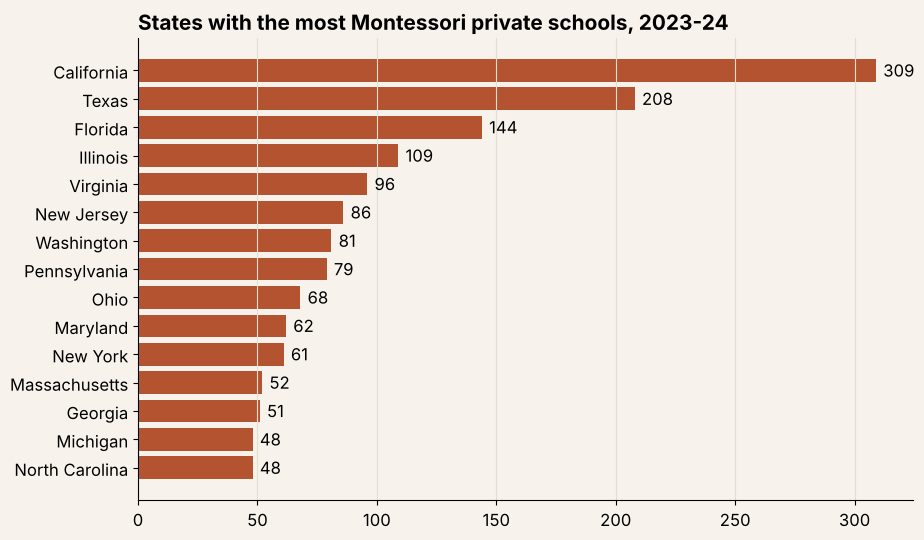

In [6]:
top = states.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.state_name, top.montessori_schools, color=TC)
for y, v in enumerate(top.montessori_schools):
    ax.text(v + 3, y, v, va="center")
ax.set_title("States with the most Montessori private schools, 2023-24", loc="left", fontsize=15, fontweight="bold")
ax.grid(axis="y", visible=False); plt.show()

In [7]:
cities.head(15)[["city", "state", "montessori_schools", "students_k12", "students_prek"]]

,city,state,montessori_schools,students_k12,students_prek
0,Houston,TX,28,1448.0,1321.0
1,Austin,TX,21,1548.0,1303.0
2,Chicago,IL,19,1376.0,1369.0
3,Portland,OR,17,779.0,832.0
4,Irvine,CA,16,338.0,1242.0
5,Cincinnati,OH,15,2593.0,859.0
6,Dallas,TX,15,2285.0,795.0
7,Miami,FL,14,804.0,885.0
8,San Jose,CA,12,173.0,499.0
9,Plano,TX,10,665.0,631.0


## 3. AMS and AMI membership

Membership is self-reported, and a school can report more than one association. Membership is not the same as accreditation. If the difference matters to you, [Montessori Theory's guide to AMI vs AMS](https://www.montessori-theory.com/ami-vs-ams-montessori-differences/) explains it for parents.

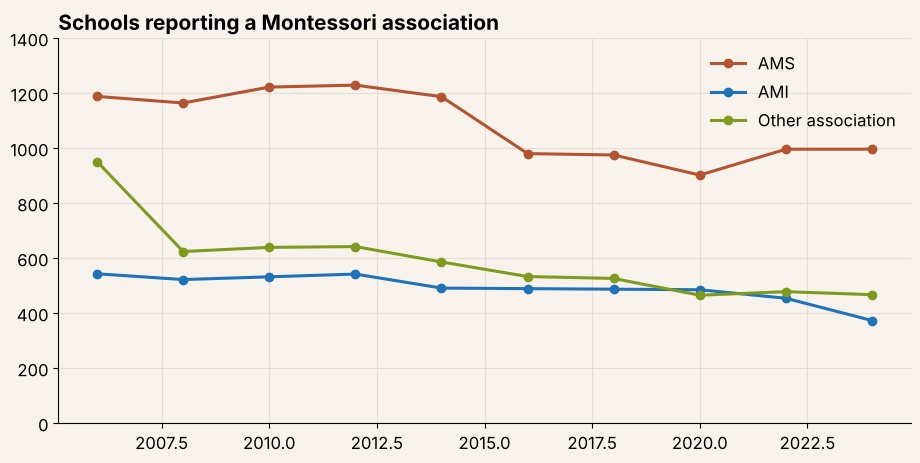

In [8]:
w = nat[nat.school_year_end >= 2006]
fig, ax = plt.subplots(figsize=(11, 5))
for col, c, lab in [("ams_member", TC, "AMS"), ("ami_member", BLUE, "AMI"), ("other_montessori_member", OLIVE, "Other association")]:
    ax.plot(w.school_year_end, w[col], color=c, lw=2.2, marker="o", label=lab)
ax.set_ylim(0, 1400); ax.legend(frameon=False)
ax.set_title("Schools reporting a Montessori association", loc="left", fontsize=15, fontweight="bold"); plt.show()

## 4. A quick map

Coordinates are published by NCES from 2005-06. This simple scatter skips Alaska and Hawaii for readability; the GeoJSON file has every school.

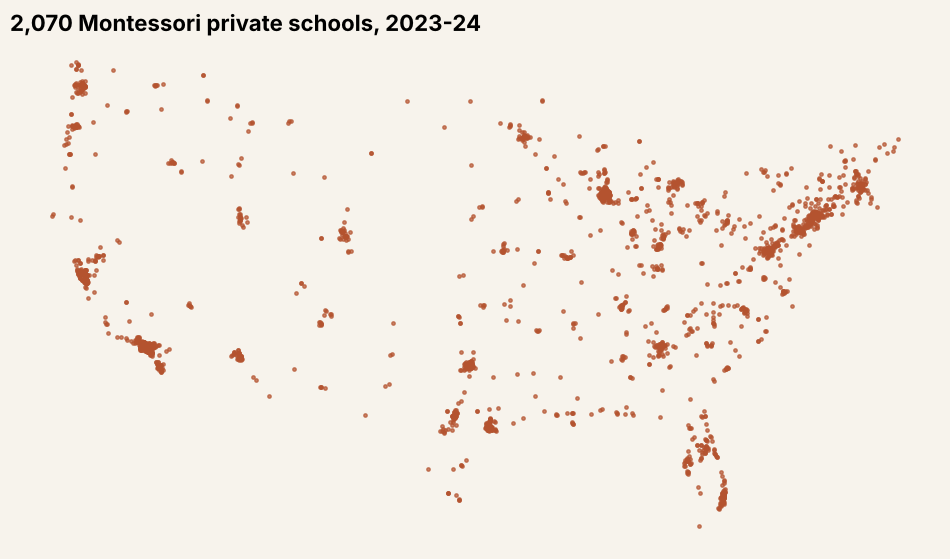

In [9]:
conus = latest[(latest.longitude > -125) & (latest.longitude < -66) & (latest.latitude > 24) & (latest.latitude < 50)]
fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(conus.longitude, conus.latitude, s=6, color=TC, alpha=0.7)
ax.set_aspect(1.25); ax.axis("off")
ax.set_title(f"{len(latest):,} Montessori private schools, 2023-24", loc="left", fontsize=16, fontweight="bold"); plt.show()

## 5. Ideas to go further

- Follow one school across waves with `school_id` (stable from the mid-1990s) and measure how long schools stay open.
- Compare Montessori schools with all private schools using `private_school_universe_totals.csv`.
- Join `county_fips` with Census population data to get schools per 100,000 children.
- Use `survey_weight` for national estimates, and read the limits in the README before comparing early waves.

**Source.** U.S. Department of Education, NCES, Private School Universe Survey, 1989-90 to 2023-24. Dataset by Montessori Theory, CC BY 4.0.